# The Finite Difference Method

**Seong Cho** · ACME Volume 4, Lab 7

**Lab objective:** approximate derivatives with finite differences written as matrices, then use them to solve linear second order boundary value problems, including singularly perturbed ones, and check the order of convergence.

<sub>Lab specification from the *Volume 4* lab manual of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the spec; the notes are condensed from it. Solutions are my own.</sub>

In [1]:
import numpy as np
import autograd.numpy as anp 
import matplotlib.pyplot as plt
from autograd import elementwise_grad as egrad
import scipy.sparse as sp

## Finite difference approximations of derivatives

A *finite difference* of $f$ is an expression $f(x+s) - f(x+t)$. Take a grid of $n+1$ evenly spaced points $a = x_{-1}, x_0, \dots, x_{n-1} = b$ with $x_i = a + (i+1)h$, $h = (b-a)/n$. The Taylor expansions

$$u(x+h) = u(x) + u'(x)h + \tfrac12 u''(x)h^2 + \tfrac16 u'''(x)h^3 + O(h^4) \qquad \textbf{(7.1)}$$
$$u(x-h) = u(x) - u'(x)h + \tfrac12 u''(x)h^2 - \tfrac16 u'''(x)h^3 + O(h^4) \qquad \textbf{(7.2)}$$

give, by subtracting and by adding them, the centered differences

$$u'(x_i) \approx \frac{u(x_{i+1}) - u(x_{i-1})}{2h}, \qquad u''(x_i) \approx \frac{u(x_{i+1}) - 2u(x_i) + u(x_{i-1})}{h^2}, \qquad i = 0, \dots, n-2,$$

both with error $O(h^2)$. Ignoring the derivatives at the endpoints, the first derivative at the interior points is a matrix product

$$\frac{1}{2h}\begin{bmatrix} -1 & 0 & 1 & & \\ & \ddots & \ddots & \ddots & \\ & & -1 & 0 & 1 \end{bmatrix}_{(n-1)\times(n+1)} \begin{bmatrix} u(x_{-1}) \\ \vdots \\ u(x_{n-1}) \end{bmatrix} = \begin{bmatrix} u'(x_0) \\ \vdots \\ u'(x_{n-2}) \end{bmatrix} \qquad \textbf{(7.3)}$$

or, moving the boundary values to a vector, with a square tridiagonal matrix

$$\frac{1}{2h}\begin{bmatrix} 0 & 1 & & \\ -1 & 0 & 1 & \\ & \ddots & \ddots & \ddots \\ & & -1 & 0 \end{bmatrix}_{(n-1)\times(n-1)} \begin{bmatrix} u(x_0) \\ \vdots \\ u(x_{n-2}) \end{bmatrix} + \begin{bmatrix} -u(x_{-1})/(2h) \\ 0 \\ \vdots \\ u(x_{n-1})/(2h) \end{bmatrix} = \begin{bmatrix} u'(x_0) \\ \vdots \\ u'(x_{n-2}) \end{bmatrix}. \qquad \textbf{(7.4)}$$

The second derivative works the same way, with the stencil $(1, -2, 1)/h^2$ in the $(n-1)\times(n+1)$ form **(7.5)**, and with the tridiagonal $(n-1)\times(n-1)$ matrix $\frac{1}{h^2}\operatorname{tridiag}(1, -2, 1)$ plus the boundary vector $\big(u(x_{-1})/h^2, 0, \dots, 0, u(x_{n-1})/h^2\big)^T$ in the form **(7.6)**.

## Problem 1: Approximating $\frac12 u'' - u'$

> **Problem 1.** Let $u(x) = \sin((x+\pi)^2 - 1)$. Use (7.3) - (7.6) to approximate $\frac12 u'' - u'$ at the grid points where $a = 0$, $b = 1$, and $n = 10$. Graph the result.

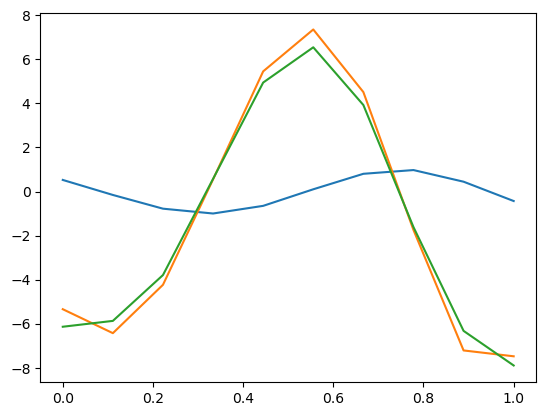

In [2]:
# What the solution should look like using 2 different methods of numeric differentiation
u = lambda x: anp.sin((x+anp.pi)**2 - 1)

x = np.linspace(0, 1, 10)
plt.plot(x, u(x))
plt.plot(x, egrad(u)(x))
plt.plot(x, np.gradient(u(x), x))
plt.show()

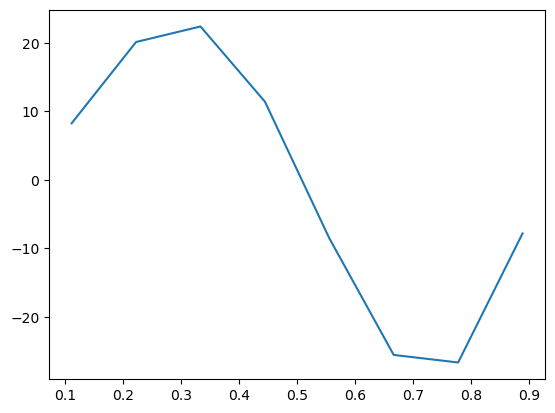

In [3]:
# Function for calculating the first derivative
def grad1(f, x):
    n = len(x)
    M = sp.diags([-1, 0, 1], [-1, 0, 1], shape=(n-2, n-2))
    h = x[1] - x[0]
    L = np.zeros(n-2)
    L[0] = -f(x[0]) / (2*h)
    L[-1] = f(x[-1]) / (2*h)
    u_prime = 1/(2*h) * M@f(x[1:-1]) + L
    return u_prime
# Function for calculating the second derivative
def grad2(f, x):
    n = len(x)
    h = x[1] - x[0]
    M = sp.diags([1, -2, 1], [-1, 0, 1], shape=(n-2, n-2))
    L = np.zeros(n-2)
    L[0] = f(x[0]) / h**2
    L[-1] = f(x[-1]) / h**2
    u_2prime = 1/(h**2) * M@f(x[1:-1]) + L
    return u_2prime
# Solve and plot
u_prime = grad1(u, x)
u_2prime = grad2(u, x)
Y_hat = (1/2) * u_2prime - u_prime
plt.plot(x[1:-1], Y_hat)
plt.show()

## Finite difference methods

Suppose instead that we know $\frac12 u'' - u' = f$ for a given $f$; how do we solve for $u$ at the grid points? Consider the boundary value problem

$$\varepsilon u''(x) - u'(x) = f(x), \quad x \in (0,1), \qquad u(0) = \alpha, \quad u(1) = \beta. \qquad \textbf{(7.7)}$$

A finite difference method approximates $U_i \approx u(x_i)$ on a grid of $N$ subintervals by replacing the differential operator $D = \varepsilon \frac{d^2}{dx^2} - \frac{d}{dx}$ with the difference operator

$$D_h U_i = \frac{\varepsilon}{h^2}(U_{i+1} - 2U_i + U_{i-1}) - \frac{1}{2h}(U_{i+1} - U_{i-1}). \qquad \textbf{(7.8)}$$

Setting $D_h U_i = f(x_i)$ for $i = 0, \dots, N-2$, with $U_{-1} = \alpha$ and $U_{N-1} = \beta$, and moving the boundary values to the right side gives a tridiagonal system:

$$\frac{1}{h^2}\begin{bmatrix} -2\varepsilon & \varepsilon - h/2 & & \\ \varepsilon + h/2 & -2\varepsilon & \varepsilon - h/2 & \\ & \ddots & \ddots & \ddots \\ & & \varepsilon + h/2 & -2\varepsilon \end{bmatrix}_{(N-1)\times(N-1)} \begin{bmatrix} U_0 \\ U_1 \\ \vdots \\ U_{N-2} \end{bmatrix} = \begin{bmatrix} f(x_0) - U_{-1}(\varepsilon + h/2)/h^2 \\ f(x_1) \\ \vdots \\ f(x_{N-2}) - U_{N-1}(\varepsilon - h/2)/h^2 \end{bmatrix}. \qquad \textbf{(7.9)}$$

## Problem 2: A singularly perturbed BVP

> **Problem 2.** Use equation (7.9) to solve the singularly perturbed BVP (7.7) with $\varepsilon = 1/10$, $f(x) = -1$, $\alpha = 1$, and $\beta = 3$. Graph the solution. This BVP is called singularly perturbed because of the location of the parameter $\varepsilon$. For $\varepsilon = 0$ the ODE has a drastically different character - it then becomes first order, and can no longer support two boundary conditions.

The solution gets steeper near $x = 1$ as $\varepsilon$ gets small.

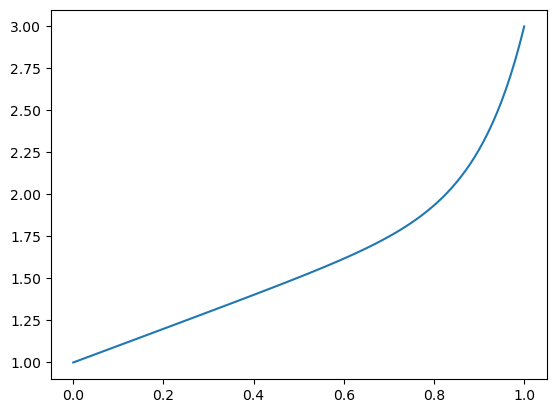

In [4]:
# Define the necessary constants/functions
eps = 1/10
f = lambda x: -1 + x*0
alpha = 1
beta = 3
n = 100

# Function that solves singularly perturbed bvp
def sp_bvp(f, eps, alpha, beta, n):
    """
    Solve for a boundary value problem of the form
    εu"(x) - u'(x) = f(x), x ∈ (0,1)
    f: callable function
    eps: scalar
    alpha: scalar left boundary condition
    beta: scalar right boundary condition
    n: number of subintervals
    """
    x = np.linspace(0, 1, n+1)    # Changed: n is the number of subintervals (n+1 grid points), not points
    h = x[1] - x[0]
    
    M = sp.diags([eps + h/2, -2*eps, eps - h/2], [-1, 0, 1], shape=(n-1, n-1)).toarray()    # Changed: n-1 interior points
    M_inv = np.linalg.inv(M)
    
    b = f(x[1:-1])
    b[0] -= alpha*(eps + h/2) / h**2
    b[-1] -= beta*(eps - h/2) / h**2
    
    U = h**2 * M_inv@b
    return np.hstack([alpha, U, beta])

# Solve and plot
x = np.linspace(0, 1, n+1)    # Changed: n+1 grid points
U = sp_bvp(f, eps, alpha, beta, n)
plt.plot(x, U)
plt.show()

A light check against the exact solution $u(x) = x + 1 - c + c\,e^{x/\varepsilon}$, $c = 1/(e^{1/\varepsilon} - 1)$:

In [5]:
xx = np.linspace(0, 1, n+1)
c = 1/(np.exp(1/eps) - 1)
print("max error vs exact solution:", np.max(np.abs(U - (xx + 1 - c + c*np.exp(xx/eps)))))

max error vs exact solution: 0.0003066740704174009


## A heuristic test for convergence

If a method is $O(h^p)$ accurate, then $E(h) \approx Ch^p$ for small $h$. Compute approximations $y_k$ for step sizes $h_1 > h_2 > \dots > h_m$ and treat the finest, $y_m$, as the true solution. Then

$$E(h_k) = \max|y_k - y_m| \approx Ch_k^p, \qquad \log E(h_k) = \log C + p\log h_k,$$

so on a log-log plot of $E(h)$ against $h$ the points lie on a line of slope $p$ once $h$ is small enough. Demonstrating second-order convergence does NOT imply that the numerical approximation is converging to the correct solution.

## Problem 3: Convergence

> **Problem 3.** Return to problem 2. How many subintervals are needed to obtain 4 digits of accuracy?
>
> This is a question about the convergence of your solution. The following code generates the log-log plot in Figure 7.2, and demonstrates second-order convergence for our finite difference approximation of (7.7). Use this code to determine what $h$ (and hence what $N$) is needed for the error to be less than $10^{-4}$. You don't need to return the value of $h$, but make sure you understand by looking at the plot.
>
> note: The function `bvp` is not provided; you need to use your code from problem 2 to define it. Make sure your function is compatible with the code below. It must take 5 parameters as input and return the solution.
>
> ```python
> num_approx = 10 # Number of Approximations
> N = 5*np.array([2**j for j in range(num_approx)])
> h, max_error = (1.-0)/N[:-1], np.ones(num_approx-1)
> # Best numerical solution, used to approximate the true solution.
> # bvp returns the grid, and the grid function, approximating the solution
> # with N subintervals of equal length.
> num_sol_best = bvp(lambda x:-1, epsilon=.1, alpha=1, beta=3, N=N[-1])
> for j in range(len(N)-1):
>     num_sol = bvp(lambda x:-1, epsilon=.1, alpha=1, beta=3, N=N[j])
>     max_error[j] = np.max(np.abs(num_sol-num_sol_best[::2**(num_approx-j-1)]))
> plt.loglog(h,max_error,'.-r',label="$E(h)$")
> plt.loglog(h,h**(2.),'-k',label="$h^{\, 2}$")
> plt.xlabel("$h$")
> plt.legend(loc='best')
> plt.show()
> print("The order of the finite difference approximation is about ",
> (np.log(max_error[0])-np.log(max_error[-1]))/(np.log(h[0])-np.log(h[-1])),
> ".")
> ```

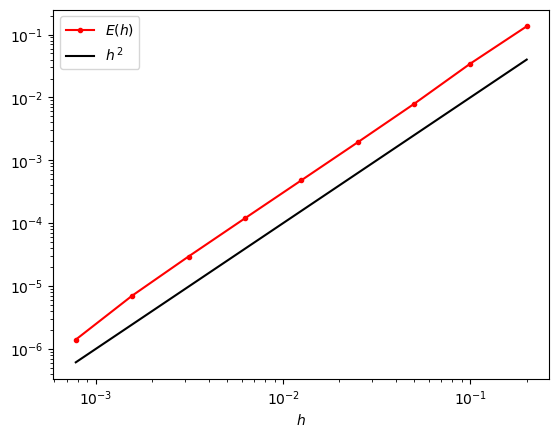

The order of the finite difference approximation is about  2.069741388527576 .


In [6]:
num_approx = 10 # Number of Approximations
N = 5*np.array([2**j for j in range(num_approx)])
h, max_error = (1.-0)/N[:-1], np.ones(num_approx-1)
# Best numerical solution, used to approximate the true solution.
# bvp returns the grid, and the grid function, approximating the solution
# with N subintervals of equal length.
num_sol_best = sp_bvp(f, eps, alpha, beta, N[-1])
for j in range(len(N)-1):
    num_sol = sp_bvp(f, eps, alpha, beta, N[j])
    max_error[j] = np.max(np.abs(num_sol-num_sol_best[::2**(num_approx-j-1)]))
plt.loglog(h,max_error,'.-r',label="$E(h)$")
plt.loglog(h,h**(2.),'-k',label=r"$h^{\, 2}$")    # [compat]: raw string avoids an invalid-escape SyntaxWarning
plt.xlabel("$h$")
plt.legend(loc='best')
plt.show()
print("The order of the finite difference approximation is about ",
(np.log(max_error[0])-np.log(max_error[-1]))/(np.log(h[0])-np.log(h[-1])),
".")

## Problem 4: General second order linear BVPs

> **Problem 4.** Extend your finite difference code to the case of a general second order linear BVP with boundary conditions (These boundary conditions are sometimes called Dirichlet conditions):
>
> $$a_1(x)y'' + a_2(x)y' + a_3(x)y = f(x), \quad x \in (a,b), \qquad y(a) = \alpha, \quad y(b) = \beta.$$
>
> Use your code to solve the boundary value problem
>
> $$\varepsilon y'' - 4(\pi - x^2)y = \cos x, \qquad y(0) = 0, \quad y(\pi/2) = 1,$$
>
> for $\varepsilon = 0.1$. Be sure to modify the finite difference operator $D_h$ in (7.8) correctly.

In [7]:
# Function to solve general linear 2nd order bvp
def linear_bvp(f, coef, alpha, beta, interval, n):
    """
    Solve for a boundary value problem of the form
    a1(x)y" + a2(x)y' + a3(x)y = f(x), x ∈ (a,b)
    f: callable function
    coef: list of callable functions, corresponding to [a1, a2, a3]
    alpha: scalar left boundary condition
    beta: scalar right boundary condition
    interval: (a,b)
    n = number of subintervals
    """
    x = np.linspace(interval[0], interval[1], n)
    h = x[1] - x[0]
    a1 = coef[0](x)
    a2 = coef[1](x)
    a3 = coef[2](x)
    
    A = (a1/(h**2)) + (a2/(2*h))
    B = (-2*a1/(h**2)) + a3
    C = (a1/(h**2)) - (a2/(2*h))
    
    M = np.diag(C[2:-1], k=-1) + np.diag(B[1:-1]) + np.diag(A[1:-2], k=1)
    M_inv = np.linalg.inv(M)
    
    b = f(x[1:-1])
    b[0] -= C[1]*alpha
    b[-1] -= A[-2]*beta    # Changed: the coefficient of U_{n-1} = beta comes from the last interior point x[-2], not x[-1]
    
    U = M_inv@b
    return np.hstack([alpha, U, beta])

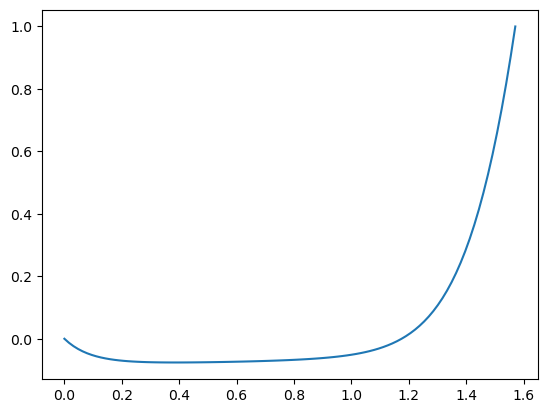

In [8]:
# Defined constants/functions
f = lambda x: np.cos(x)
a1 = lambda x: 0.1 + x*0
a2 = lambda x: x*0
a3 = lambda x: -4*(np.pi - x**2)
interval = (0, np.pi/2)
alpha = 0
beta = 1
n = 100
# Solve and plot
U = linear_bvp(f, [a1,a2,a3], alpha, beta, interval, n)
x = np.linspace(interval[0], interval[1], n)
plt.plot(x, U)
plt.show()

The next few problems will help you test your finite difference code.

## Problem 5: Testing the solver

> **Problem 5.** Numerically solve the boundary value problem
>
> $$\varepsilon y'' + xy' = -\varepsilon\pi^2\cos(\pi x) - \pi x\sin(\pi x), \qquad y(-1) = -2, \quad y(1) = 0,$$
>
> for $\varepsilon = 0.1$, $0.01$, and $0.001$.

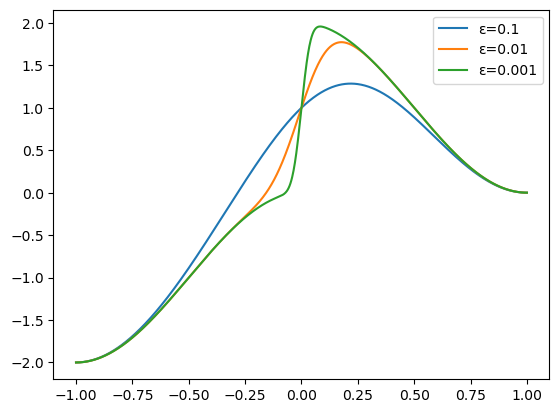

In [9]:
# Defined constants/functions
f = lambda x: -eps*(np.pi**2)*np.cos(np.pi*x) - np.pi*x*np.sin(np.pi*x)
a1 = lambda x: eps + x*0
a2 = lambda x: x
a3 = lambda x: x*0
interval = (-1, 1)
alpha = -2
beta = 0
n = 1000
# Solve and plot for given epsilon
for eps in [0.1, 0.01, 0.001]:  
    U = linear_bvp(f, [a1,a2,a3], alpha, beta, interval, n)
    x = np.linspace(interval[0], interval[1], n)
    plt.plot(x, U, label="ε="+str(eps))
plt.legend()
plt.show()

A light check against the exact solution $y(x) = \cos(\pi x) + \operatorname{erf}\big(x/\sqrt{2\varepsilon}\big)/\operatorname{erf}\big(1/\sqrt{2\varepsilon}\big)$:

In [10]:
from scipy.special import erf
for eps in [0.1, 0.01, 0.001]:
    U = linear_bvp(f, [a1,a2,a3], alpha, beta, interval, n)
    exact = np.cos(np.pi*x) + erf(x/np.sqrt(2*eps))/erf(1/np.sqrt(2*eps))
    print(f"eps = {eps}: max error vs exact solution = {np.max(np.abs(U - exact)):.2e}")

eps = 0.1: max error vs exact solution = 1.23e-05


eps = 0.01: max error vs exact solution = 3.75e-05
eps = 0.001: max error vs exact solution = 2.64e-04


## Problem 6: A second test

> **Problem 6.** Numerically solve the boundary value problem
>
> $$(\varepsilon + x^2)y'' + 4xy' + 2y = 0, \qquad y(-1) = 1/(1+\varepsilon), \quad y(1) = 1/(1+\varepsilon),$$
>
> for $\varepsilon = 0.05$, $0.02$.

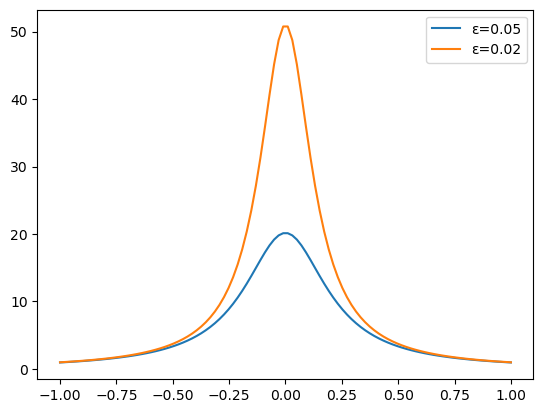

In [11]:
# Defined constants/functions
f = lambda x: x*0
a1 = lambda x: eps + x**2
a2 = lambda x: 4*x
a3 = lambda x: 2 + x*0
interval = (-1, 1)
alpha = 1/(1+eps)
beta = 1/(1+eps)
n = 100
# Solve for each epsilon and plot
for eps in [0.05, 0.02]:  
    alpha = beta = 1/(1+eps)    # Changed: the boundary values depend on eps, so set them inside the loop
    U = linear_bvp(f, [a1,a2,a3], alpha, beta, interval, n)
    x = np.linspace(interval[0], interval[1], n)
    plt.plot(x, U, label="ε="+str(eps))
plt.legend()
plt.show()

A light check against the exact solution $y(x) = 1/(\varepsilon + x^2)$:

In [12]:
for eps in [0.05, 0.02]:
    alpha = beta = 1/(1+eps)
    U = linear_bvp(f, [a1,a2,a3], alpha, beta, interval, n)
    print(f"eps = {eps}: max error vs exact solution = {np.max(np.abs(U - 1/(eps + x**2))):.2e}")

eps = 0.05: max error vs exact solution = 1.56e-01
eps = 0.02: max error vs exact solution = 1.01e+00
